# Multiscale Lorenz 96 System

System of Thornes et al. (2017), as coded by Chattopadhyay et al.:

$$\frac{dX_k}{dt} = X_{k-1}(X_{k+1}-X_{k-2}) - X_k + F - \frac{hc}{b}\sum_j Y_{j,k}$$
$$\frac{dY_{j,k}}{dt} = -cb\,Y_{j+1,k}(Y_{j+2,k}-Y_{j-1,k}) - c\,Y_{j,k} + \frac{hc}{b}X_k - \frac{he}{d}\sum_i Z_{i,j,k}$$
$$\frac{dZ_{i,j,k}}{dt} = ed\,Z_{i-1,j,k}(Z_{i+1,j,k}-Z_{i-2,j,k}) - g\,e\,Z_{i,j,k} + \frac{he}{d}Y_{j,k}$$

Each $X_k$ has its own $J$ variables $Y$, and each $Y_{j,k}$ has its own $I$ variables $Z$ (periodicity within each sector).

In [145]:
import numpy as np
import matplotlib.pyplot as plt

USE_Y = False        # False -> X only = classic Lorenz 96 (the coupling term vanishes)
USE_Z = True        # False -> X + Y only (2 levels). Ignored if USE_Y = False.
USE_Z = USE_Y and USE_Z

K, J, I = 8, 8, 8   # nb of X ; nb of Y per X ; nb of Z per Y

F = 20.0            # forcing of X
h = 1.0             # strength of ALL couplings (0 = decoupled levels)
b, c = 10.0, 10.0   # Y : c = X/Y time-scale ratio (large c -> fast Y),
                    #     b = X/Y amplitude ratio
d, e = 10.0, 10.0   # Z : same role as b, c but between Y and Z
g = 10.0             # damping of Z.

dt       = 0.005    # RK4 step (do not increase if c or e are large)
N_LT     = 100       # plotted duration in Lyapunov times
LAMBDA   = 4.5      # Lyapunov exponent used to convert LT -> time (paper : 4.5/MTU)
SPIN_UP  = 20.0     # duration discarded at the start (in MTU), to leave the transient
SEED     = 0

In [146]:
# --- derivatives of the 1-, 2- or 3-level system (missing blocks are None) ---
def rhs(X, Y, Z):
    """Derivatives. X:(K,)  Y:(J,K) or None  Z:(J,K,I) or None."""
    dX = np.roll(X, 1)*(np.roll(X, -1) - np.roll(X, 2)) - X + F
    dY = dZ = None
    if Y is not None:
        dX = dX - h*c/b * Y.sum(0)
        dY = (-c*b*np.roll(Y, -1, 0)*(np.roll(Y, -2, 0) - np.roll(Y, 1, 0))
              - c*Y + h*c/b * X[None, :])
        if Z is not None:
            dY = dY - h*e/d * Z.sum(2)
            dZ = (e*d*np.roll(Z, 1, 2)*(np.roll(Z, -1, 2) - np.roll(Z, 2, 2))
                  - g*e*Z + h*e/d * Y[:, :, None])
    return dX, dY, dZ


# --- S + a*dS, block by block, preserving the None blocks ---
def add(S, dS, a):
    return tuple(None if s is None else s + a*ds for s, ds in zip(S, dS))


# --- one Runge-Kutta 4 step on the full state (X, Y, Z) ---
def rk4(S):
    k1 = rhs(*S); k2 = rhs(*add(S, k1, dt/2)); k3 = rhs(*add(S, k2, dt/2)); k4 = rhs(*add(S, k3, dt))
    return tuple(None if s is None else s + dt/6*(a + 2*b_ + 2*c_ + d_)
                 for s, a, b_, c_, d_ in zip(S, k1, k2, k3, k4))

In [147]:
# ------------------------------ dimensions ------------------------------
nX, nY, nZ = K, (K*J if USE_Y else 0), (K*J*I if USE_Z else 0)

print("=== DIMENSIONS ===")
print(f"X : K = {K} variables")
print(f"Y : " + (f"J x K = {J} x {K} = {nY} variables  ({J} per X)" if USE_Y else "disabled"))
print(f"Z : " + (f"I x J x K = {I} x {J} x {K} = {nZ} variables  ({I} per Y)" if USE_Z else "disabled"))
print(f"total : {nX + nY + nZ} variables  ->  "
      + ("classic Lorenz 96" if not USE_Y else "2 levels (X,Y)" if not USE_Z else "3 levels (X,Y,Z)"))

# ------------------------------ simulation ------------------------------
rng = np.random.default_rng(SEED)
S = (rng.integers(-5, 6, K).astype(float),
     rng.standard_normal((J, K)) if USE_Y else None,
     0.05*rng.standard_normal((J, K, I)) if USE_Z else None)

for _ in range(int(SPIN_UP/dt)):
    S = rk4(S)

T_total = N_LT / LAMBDA
n_steps = int(round(T_total/dt))
t  = np.arange(n_steps)*dt
Xs = np.empty((n_steps, K))
Ys = np.empty((n_steps, J, K)) if USE_Y else None
Zs = np.empty((n_steps, J, K, I)) if USE_Z else None
for n in range(n_steps):
    S = rk4(S)
    Xs[n] = S[0]
    if USE_Y: Ys[n] = S[1]
    if USE_Z: Zs[n] = S[2]
    if not np.isfinite(S[0]).all():
        raise FloatingPointError(f"divergence at step {n} : lower dt")

print(f"\n=== TIME UNIT===\n{N_LT} LT = {T_total:.2f} MTU = {n_steps} steps of dt = {dt}  "
      f"(1 LT = {1/LAMBDA:.3f} MTU = {1/LAMBDA/dt:.0f} steps)")

print("\n=== AMPLITUDES (std dev, [min, max]) ===")
for name, A in (("X", Xs), ("Y", Ys), ("Z", Zs)):
    if A is not None:
        print(f"{name} : {A.std():.4f}   [{A.min():+.4f}, {A.max():+.4f}]")
if USE_Y:
    print(f"\ncoupling (hc/b)*sum_j Y : rms = {np.sqrt(np.mean((h*c/b*Ys.sum(1))**2)):.2f}   "
          f"vs advection of X : rms = "
          f"{np.sqrt(np.mean((np.roll(Xs,1,1)*(np.roll(Xs,-1,1)-np.roll(Xs,2,1)))**2)):.2f}")

=== DIMENSIONS ===
X : K = 8 variables
Y : disabled
Z : disabled
total : 8 variables  ->  classic Lorenz 96

=== TIME UNIT===
100 LT = 22.22 MTU = 4444 steps of dt = 0.005  (1 LT = 0.222 MTU = 44 steps)

=== AMPLITUDES (std dev, [min, max]) ===
X : 7.2191   [-19.5804, +23.5312]


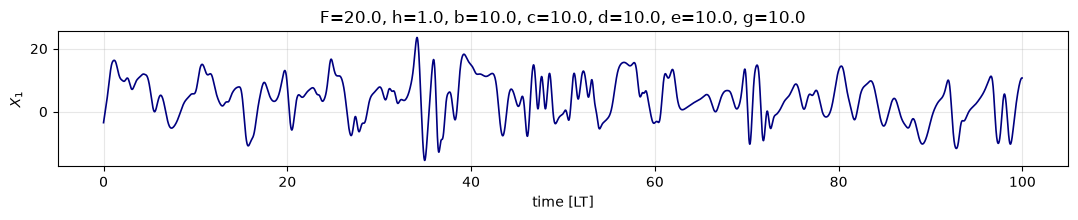

In [148]:
# ------------------------------ time series (cf. Fig. 1 of the paper) ------------------------------
tl = t*LAMBDA                                   # Lyapunov-time axis
rows = [("$X_1$", Xs[:, 0], "navy")]
if USE_Y: rows.append(("$Y_{1,1}$", Ys[:, 0, 0], "red"))
if USE_Z: rows.append(("$Z_{1,1,1}$", Zs[:, 0, 0, 0], "limegreen"))

fig, ax = plt.subplots(len(rows), 1, figsize=(11, 2.3*len(rows)), sharex=True, squeeze=False)
for a, (lab, y, col) in zip(ax[:, 0], rows):
    a.plot(tl, y, color=col, lw=1.2); a.set_ylabel(lab); a.grid(alpha=.3)
ax[-1, 0].set_xlabel("time [LT]")
ax[0, 0].set_title(f"F={F}, h={h}, b={b}, c={c}, d={d}, e={e}, g={g}")
plt.tight_layout(); plt.show()

# X_1 and its sum of Y : how much of the dynamics of X comes from Y ?
if USE_Y:
    fig, ax = plt.subplots(figsize=(11, 2.6))
    ax.plot(tl, Xs[:, 0], "navy", lw=1.2, label="$X_1$")
    ax.plot(tl, h*c/b*Ys[:, :, 0].sum(1), "red", lw=1, label=r"$\frac{hc}{b}\sum_j Y_{j,1}$ (coupling)")
    ax.set_xlabel("time [LT]"); ax.legend(loc="upper right"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

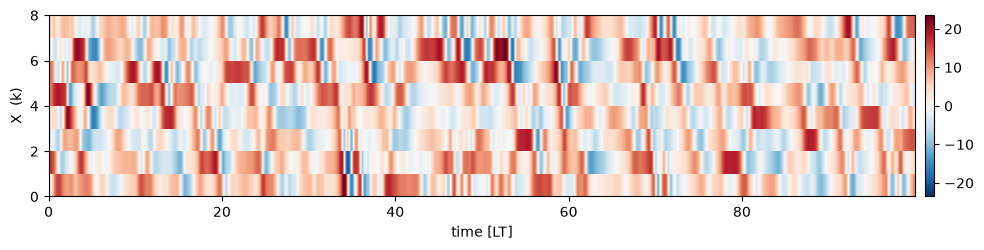

In [149]:
# ------------------------------ space-time view (Hovmoller) ------------------------------
maps = [("X  (k)", Xs.T, K)]
if USE_Y: maps.append(("Y  (j,k) -> j + J*k", Ys.transpose(0, 2, 1).reshape(n_steps, -1).T, K*J))
if USE_Z: maps.append(("Z  (i,j,k), 1 out of 8", Zs.transpose(0, 2, 1, 3).reshape(n_steps, -1)[:, ::8].T, K*J*I//8))

fig, ax = plt.subplots(len(maps), 1, figsize=(11, 2.6*len(maps)), sharex=True, squeeze=False)
for a, (lab, M, n) in zip(ax[:, 0], maps):
    v = np.abs(M).max()
    im = a.imshow(M, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-v, vmax=v,
                  extent=[tl[0], tl[-1], 0, n], interpolation="nearest")   # no smoothing
    if n > K:                                   # lines = boundaries between sectors k
        for kk in range(1, K): a.axhline(kk*n/K, color="k", lw=.4, alpha=.5)
    a.set_ylabel(lab); plt.colorbar(im, ax=a, pad=.01)
ax[-1, 0].set_xlabel("time [LT]")
plt.tight_layout(); plt.show()

# Quantum reservoir simple example

Here we used a simplified version of RF_QRC from the [reference paper](https://arxiv.org/abs/2405.03390).

The reservoir state is never re-encoded: each step starts from a freshly prepared state and only the current input is encoded.
The memory comes entirely from the classical leaky integration of the measured probabilities, and only the ridge readout is trained.

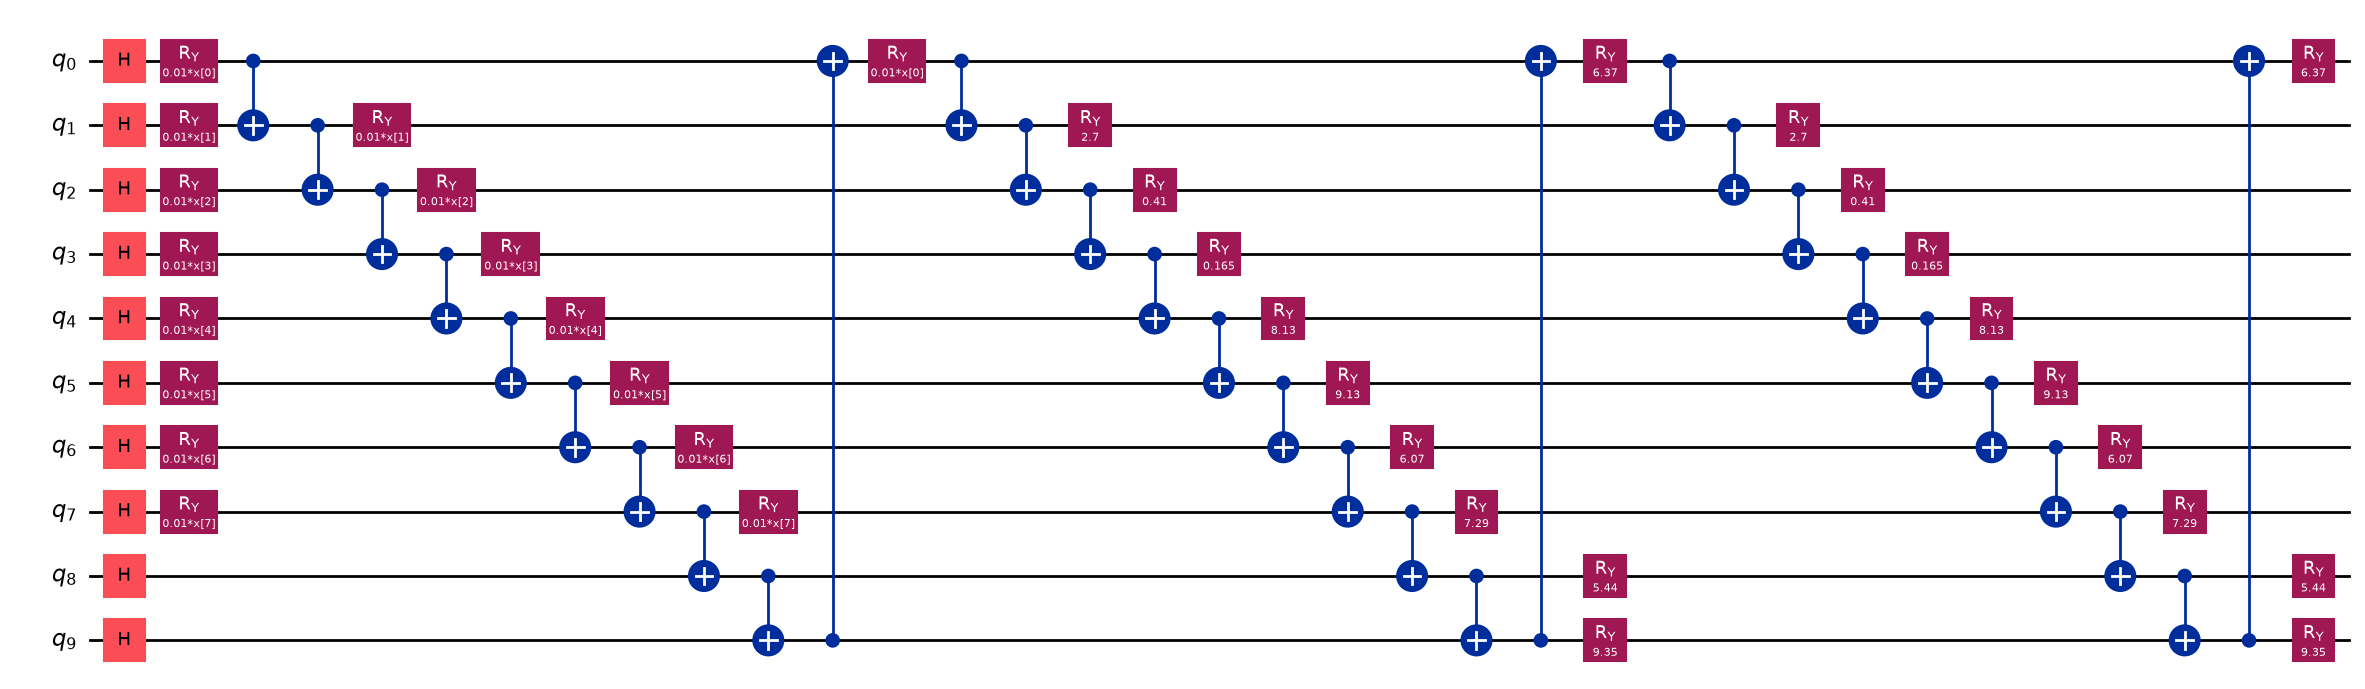

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector

N_QUBITS = 10
LAM = 0.01
ALPHA_RANGE = 10
SEED = 0


def full_cnot(c, n_qubits):
    for i in range(n_qubits):
        for j in range(i + 1, n_qubits):
            c.cx(i, j)

def ring_cnot(c, n_qubits):
    for i in range(n_qubits):
        c.cx(i, (i + 1) % n_qubits)


def build_circuit(n_qubits=N_QUBITS, lam=LAM, alpha_range=ALPHA_RANGE, seed=SEED):
    rng_c = np.random.default_rng(seed)
    alpha = rng_c.uniform(0, alpha_range, n_qubits)
    x = ParameterVector("x", K)

    # circuit description

    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))

    # encoding
    for q in range(len(x)):
        qc.ry(lam * x[q], q)

    # full_cnot(qc, n_qubits)
    ring_cnot(qc, n_qubits)

    # re-encoding
    for q in range(len(x)):
        qc.ry(lam * x[q], q)

    # full_cnot(qc, n_qubits)
    ring_cnot(qc, n_qubits)

    # random reservoir evolution
    for q in range(n_qubits):
        qc.ry(alpha[q], q)
    # full_cnot(qc, n_qubits)
    ring_cnot(qc, n_qubits)
    for q in range(n_qubits):
        qc.ry(alpha[q], q)

    def circuit(u):
        return Statevector(qc.assign_parameters({x: np.asarray(u)})).probabilities()

    return circuit, qc


circuit, qc = build_circuit()

qc.draw('mpl', fold=-1)

In [151]:
N_LYAP = int(1/LAMBDA/dt)      # number of RK4 steps in one Lyapunov time
N_WASH = 2 * N_LYAP            # washout length: reservoir transient discarded
N_PRED = 8 * N_LYAP            # forecast horizon used to measure the VPT
C0 = n_steps - N_PRED - 1      # end of the training window (all the rest is train)
SIGMA = Xs.std()               # std of the data, normalises the NRMSE
dim = K                        # number of predicted variables (the slow X only)
TEST_STARTS = [C0]             # indices from which the closed-loop forecasts start

EPSILON = 0.15                 # leak rate of the reservoir
TIKH = 1e-8                     # Tikhonov regularisation of the ridge regression
DIM = 2 ** N_QUBITS            # size of the reservoir state (probability vector)

In [152]:
# --- training ---------------------------------------------------------------
def train(circuit, eps=EPSILON, tikh=TIKH):
    R = np.zeros((C0 - 1, DIM))
    r = np.zeros(DIM)
    for t in range(1, C0):
        r = (1 - eps) * r + eps * circuit(Xs[t])
        R[t-1] = r

    Xf = np.hstack([R[N_WASH:-1], np.ones((len(R) - N_WASH - 1, 1))])
    Yt = Xs[N_WASH + 2:C0]
    W_out = np.linalg.solve(Xf.T @ Xf + tikh * np.eye(DIM + 1), Xf.T @ Yt)

    print("train 1-step NRMSE:", np.sqrt(np.mean((Xf @ W_out - Yt)**2)) / SIGMA)
    return W_out


W_out = train(circuit)

# --- test -------------------------------------------------------------------
def predict(circuit, W_out, start, n_steps, eps=EPSILON):
    r = np.zeros(DIM)
    for t in range(start - N_WASH, start + 1):
        r = (1 - eps) * r + eps * circuit(Xs[t])

    preds = np.zeros((n_steps, dim))
    for k in range(n_steps):
        u = np.append(r, 1.0) @ W_out
        preds[k] = u
        r = (1 - eps) * r + eps * circuit(u)
    return preds


def evaluate(circuit, W_out, eps=EPSILON):
    PRED_SV = []
    vpts = []
    for s in TEST_STARTS:
        p = predict(circuit, W_out, s, N_PRED, eps)
        PRED_SV.append(p)
        nrmse = np.sqrt(np.mean((p - Xs[s+1:s+1+N_PRED])**2, axis=1)) / SIGMA
        bad = nrmse > 0.5
        vpts.append((bad.argmax() if bad.any() else N_PRED) / N_LYAP)

    PRED_SV = np.array(PRED_SV)
    print("VPT:", np.mean(vpts), "+/-", np.std(vpts))
    return PRED_SV, np.mean(vpts)


PRED_SV, vpt = evaluate(circuit, W_out)

train 1-step NRMSE: 0.0016254669980620032
VPT: 4.318181818181818 +/- 0.0


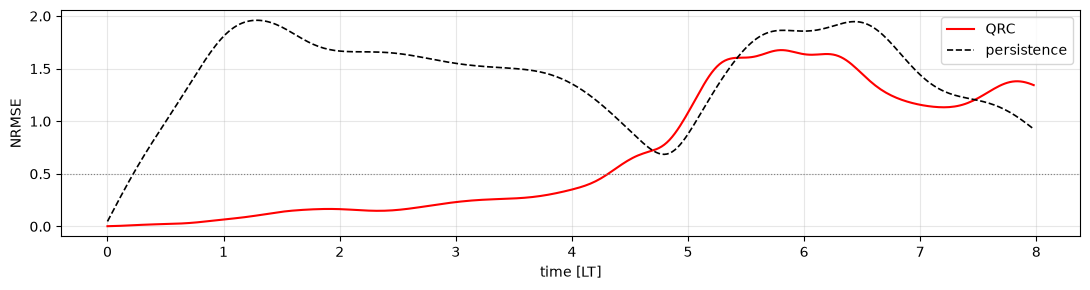

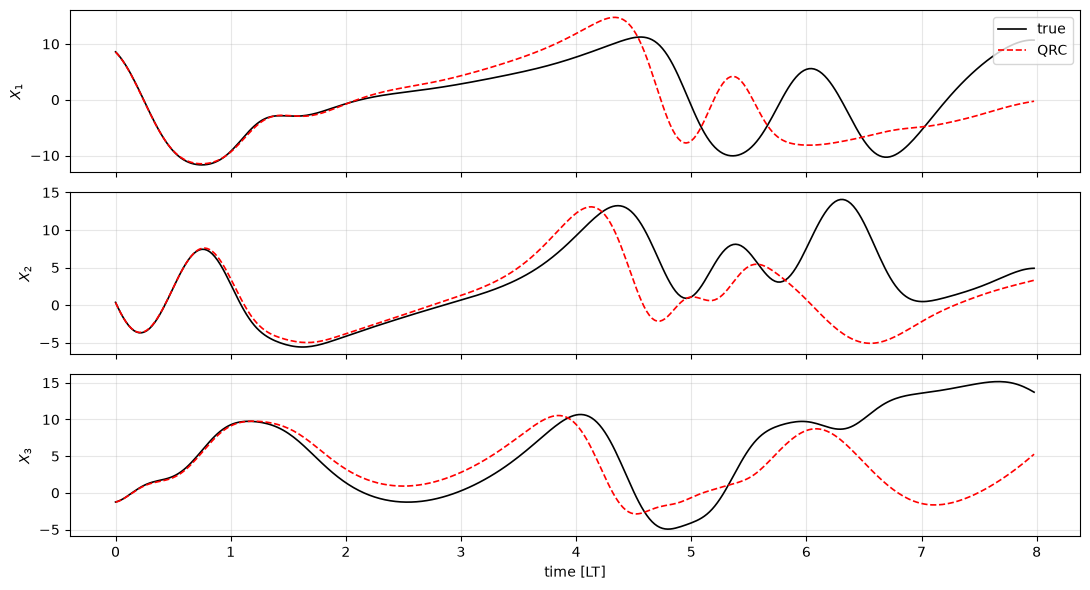

In [153]:
s = TEST_STARTS[0]
true = Xs[s+1:s+1+N_PRED]                       # ground truth over the forecast window
pred = PRED_SV[0]                               # closed-loop QRC forecast
pers = np.tile(Xs[s], (N_PRED, 1))              # persistence baseline: keep last state
tl_pred = np.arange(N_PRED) / N_LYAP            # time axis in Lyapunov times

err_qrc = np.sqrt(np.mean((pred - true)**2, axis=1)) / SIGMA
err_per = np.sqrt(np.mean((pers - true)**2, axis=1)) / SIGMA

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(tl_pred, err_qrc, "r", lw=1.5, label="QRC")
ax.plot(tl_pred, err_per, "k--", lw=1.2, label="persistence")
ax.axhline(0.5, color="gray", lw=.8, ls=":")
ax.set_xlabel("time [LT]"); ax.set_ylabel("NRMSE"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for a, k in zip(ax, range(3)):
    a.plot(tl_pred, true[:, k], "k", lw=1.2, label="true")
    a.plot(tl_pred, pred[:, k], "r--", lw=1.2, label="QRC")
    a.set_ylabel(f"$X_{k+1}$"); a.grid(alpha=.3)
ax[0].legend(loc="upper right")
ax[-1].set_xlabel("time [LT]")
plt.tight_layout(); plt.show()